# Vehicle Number Plate Detection & Classification Using Deep Learning

This notebook implements a two-stage approach to Vehicle Number Plate analysis:
1. **Baseline CNN (Classification):** Categorizes images into 'Clear Plate' or 'Difficult Plate'.
2. **YOLOv8 & Classical CV (Detection):** Localizes the exact position of the number plate within the image.

## Step 1: Importing Required Libraries
In this cell, we import all necessary Python libraries for data manipulation, computer vision, deep learning, and evaluation metrics.

In [ ]:
# System and utility imports
import os
import shutil
import random
from pathlib import Path
from itertools import cycle

# Data Science and CV imports
import numpy as np
import matplotlib.pyplot as plt
import cv2

# Deep Learning imports
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score

## Step 2: Environment Setup and Directory Configuration
Here we mount Google Drive to access the dataset and define the root paths for our two target classes.

In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Define base paths
root_path = Path('/content/drive/MyDrive/Colab Notebooks/Vehicle Number Plate Detection Dataset')
clear_plate_path = root_path / 'clear_plate'
difficult_plate_path = root_path / 'difficult_plate'

print(f"Dataset accessible: {root_path.exists()}")

Dataset accessible: True


In [ ]:
# Function to check a folder and count its files
def check_folder(folder_path, name):
    if folder_path.exists():
        file_count = len(os.listdir(folder_path))
        print(f"{name}: True ({file_count} items)")
    else:
        print(f"{name}: False (0 items)")

# Check dataset folders
check_folder(clear_plate_path, "Clear Plate Folder Exists")
check_folder(difficult_plate_path, "Difficult Plate Folder Exists")

Clear Plate Folder Exists: True (646 items)
Difficult Plate Folder Exists: True (646 items)


## Step 3: Data Loading for CNN Classification
We load the image data from the directories. We explicitly define the 'classes' parameter to ensure the model only picks up the 'clear_plate' and 'difficult_plate' folders, ignoring any extraneous data.

In [ ]:
# Model and training configurations
img_size = (224, 224)
batch_size = 32
seed = 42
target_classes = ['clear_plate', 'difficult_plate']

In [ ]:
# Load training data (70%)
train_data = tf.keras.utils.image_dataset_from_directory(
    root_path,
    validation_split=0.3,
    subset="training",
    seed=seed,
    image_size=img_size,
    batch_size=batch_size,
    class_names=target_classes
)

Found 1292 files belonging to 2 classes.
Using 905 files for training.


In [ ]:
# Load temporary validation data (30%) to be split later
temp_data = tf.keras.utils.image_dataset_from_directory(
    root_path,
    validation_split=0.3,
    subset="validation",
    seed=seed,
    image_size=img_size,
    batch_size=batch_size,
    class_names=target_classes
)

Found 1292 files belonging to 2 classes.
Using 387 files for validation.


## Step 4: Data Preprocessing and Pipeline Optimization
We split the temporary 30% validation set equally into validation (15%) and testing (15%) sets. Then, we apply TensorFlow's prefetch method to optimize data loading performance during training.

In [ ]:
# Split the 30% validation data equally into validation (15%) and test (15%)
num_batches = tf.data.experimental.cardinality(temp_data).numpy()
val_data = temp_data.take(num_batches // 2)
test_data = temp_data.skip(num_batches // 2)

print("Dataset successfully split into Validation and Test (15% Each).")

Dataset successfully split into Validation and Test (15% Each).


In [ ]:
# Optimize data loading pipelines for performance
AUTOTUNE = tf.data.AUTOTUNE
train_data = train_data.prefetch(buffer_size=AUTOTUNE)
val_data = val_data.prefetch(buffer_size=AUTOTUNE)
test_data = test_data.prefetch(buffer_size=AUTOTUNE)

## Step 5: Building the Baseline CNN Architecture
In this step, we construct the Convolutional Neural Network. We include a data augmentation layer to prevent overfitting and use a softmax activation function in the final dense layer for classification.

In [ ]:
# Data augmentation to prevent overfitting (More Augmentation = Model Generalizes Better)
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomBrightness(0.1),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomContrast(0.1),
])

In [ ]:
# Baseline CNN Architecture
model = tf.keras.Sequential([

    # Input layer
    tf.keras.layers.Input(shape=(img_size[0], img_size[1], 3)),

    # Apply augmentation and normalize pixel values
    data_augmentation,
    tf.keras.layers.Rescaling(1./255),

    # Convolution blocks (Feature extraction blocks)
    tf.keras.layers.Conv2D(32, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(64, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(128, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(256, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    # Classification head
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dropout(0.3),  # helps reduce overfitting

    # Using softmax for classification
    tf.keras.layers.Dense(len(target_classes), activation="softmax")
])

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36864)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     9,437,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           514 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,826,370 (37.48 MB)

 Trainable params: 9,826,370 (37.48 MB)

 Non-trainable params: 0 (0.00 B)

## Step 6: Training the CNN Model
We fit the compiled CNN model to our training data and validate it against our validation dataset for 50 epochs.

In [ ]:
# Train the model
epochs = 50
history = model.fit(
    train_data,
    validation_data=val_data,
    batch_size=32,
    epochs=epochs
)

Epoch 1/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 67s 2s/step - accuracy: 0.4961 - loss: 0.7046 - val_accuracy: 0.4427 - val_loss: 0.7039
Epoch 2/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 11s 381ms/step - accuracy: 0.5204 - loss: 0.6927 - val_accuracy: 0.4427 - val_loss: 0.6959
Epoch 3/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 10s 332ms/step - accuracy: 0.5160 - loss: 0.6933 - val_accuracy: 0.5677 - val_loss: 0.6911
Epoch 4/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 6s 192ms/step - accuracy: 0.5337 - loss: 0.6917 - val_accuracy: 0.4688 - val_loss: 0.6960
Epoch 5/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 7s 255ms/step - accuracy: 0.5249 - loss: 0.6901 - val_accuracy: 0.5417 - val_loss: 0.6948
Epoch 6/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 8s 187ms/step - accuracy: 0.5293 - loss: 0.6945 - val_accuracy: 0.4531 - val_loss: 0.6948
Epoch 7/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 7s 234ms/step - accuracy: 0.5326 - loss: 0.6922 - val_accuracy: 0.5156 - val_loss: 0.6923
Epoch 8/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 5s 180ms/step - accuracy: 0.5271 - loss: 0.6908 - val_accuracy: 0.

## Step 7: Evaluating CNN Performance
We extract the training history to visualize the model's loss and accuracy curves over the trained epochs. This helps us understand if the model is learning effectively or overfitting.

### Step 7a: Evaluating Model Loss
We extract the training history to visualize the model's loss curve over the trained epochs to check for convergence or overfitting.

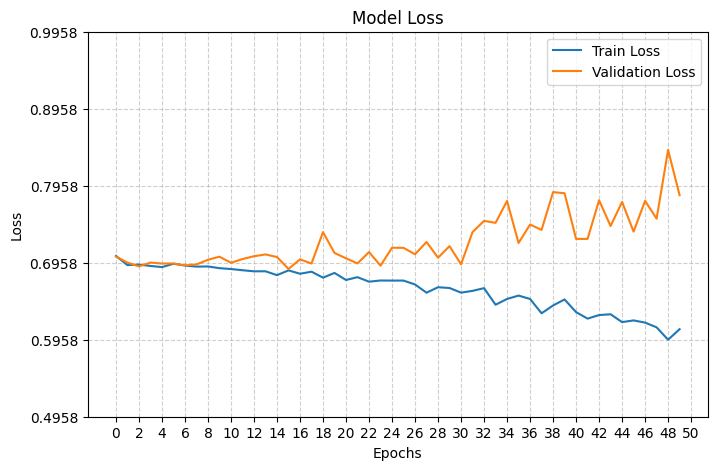

In [ ]:
# Evaluate and plot model loss visually
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

# Calculate min and max loss dynamically
min_loss = min(min(history.history['loss']), min(history.history['val_loss']))
max_loss = max(max(history.history['loss']), max(history.history['val_loss']))

# Set dynamic y-axis ticks based on the calculated min and max values
# We subtract/add a small buffer (0.1) for better visualization, ensuring the minimum doesn't drop below 0
lower_bound = max(0, min_loss - 0.1)
upper_bound = max_loss + 0.2
plt.yticks(np.arange(lower_bound, upper_bound, 0.1))

# Set dynamic x-axis ticks to show every 2 epochs
epochs = len(history.history['loss'])
plt.xticks(np.arange(0, epochs + 2, 2))

plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### Step 7b: Evaluating Model Accuracy
Next, we plot the training and validation accuracy across epochs to see how well the model is learning to classify the images.

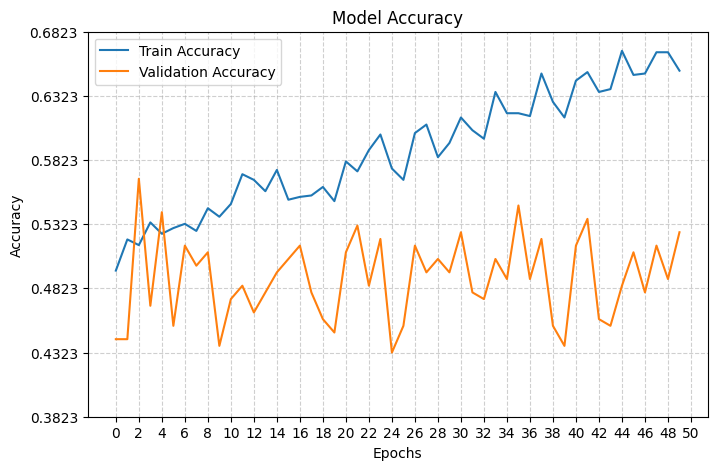

In [ ]:
# Evaluate and plot model accuracy visually
plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

# Calculate min and max accuracy dynamically for y-axis scaling
min_acc = min(min(history.history['accuracy']), min(history.history['val_accuracy']))
max_acc = max(max(history.history['accuracy']), max(history.history['val_accuracy']))

# Set dynamic y-axis ticks
# We provide a small buffer (0.05) and ensure the upper bound doesn't exceed 1.0 (100% accuracy)
lower_bound_acc = max(0, min_acc - 0.05)
upper_bound_acc = min(1.0, max_acc + 0.05)
plt.yticks(np.arange(lower_bound_acc, upper_bound_acc, 0.05))

# Set dynamic x-axis ticks to show every 2 epochs
epochs = len(history.history['accuracy'])
plt.xticks(np.arange(0, epochs + 2, 2))

plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### Step 7c: Confusion Matrix and Classification Report
The confusion matrix allows us to see exactly where the model is making misclassifications (e.g., mistaking a difficult plate for a clear one). The classification report provides key metrics such as Precision, Recall, and F1-Score for each class.

In [ ]:
# Prepare true and predicted labels from the test dataset
y_true, y_pred = [], []

for images, labels in test_data:
    # Predict probabilities for the batch
    predictions = model.predict(images, verbose=0)

    # Convert labels and predictions to class indices
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

# Compute and plot confusion matrix
cm = confusion_matrix(y_true, y_pred)
present_classes = sorted(np.unique(y_true))
display_labels = [target_classes[i] for i in present_classes]

<Figure size 800x600 with 0 Axes>

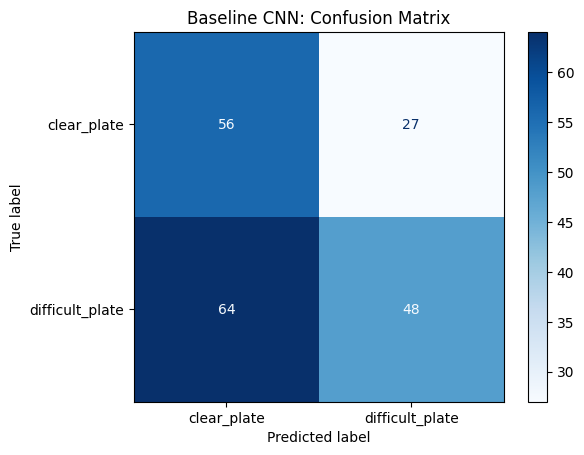

In [ ]:
# Print confusion matrix
plt.figure(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=display_labels)
disp.plot(cmap=plt.cm.Blues, values_format='d')
plt.title('Baseline CNN: Confusion Matrix')
plt.show()

In [ ]:
# Print detailed classification metrics
print("Classification Report:\n")
print(classification_report(y_true, y_pred, target_names=display_labels))

Classification Report:

                 precision    recall  f1-score   support

    clear_plate       0.47      0.67      0.55        83
difficult_plate       0.64      0.43      0.51       112

       accuracy                           0.53       195
      macro avg       0.55      0.55      0.53       195
   weighted avg       0.57      0.53      0.53       195



### Step 7d: ROC Curve and AUC Score
The Receiver Operating Characteristic (ROC) curve illustrates the diagnostic ability of our binary classifier. The Area Under the Curve (AUC) provides an aggregate measure of performance across all possible classification thresholds.

In [ ]:
# Collect true labels and predicted probabilities for ROC calculation
y_true_list = []
y_prob_list = []

for images, labels in test_data:
    y_true_list.extend(labels.numpy())
    y_prob_list.extend(model.predict(images, verbose=0))

y_true_arr = np.array(y_true_list)
y_prob_arr = np.array(y_prob_list)

# One-hot encode true labels
y_true_onehot = tf.keras.utils.to_categorical(y_true_arr, num_classes=len(target_classes))
present_classes = sorted(np.unique(y_true_arr))

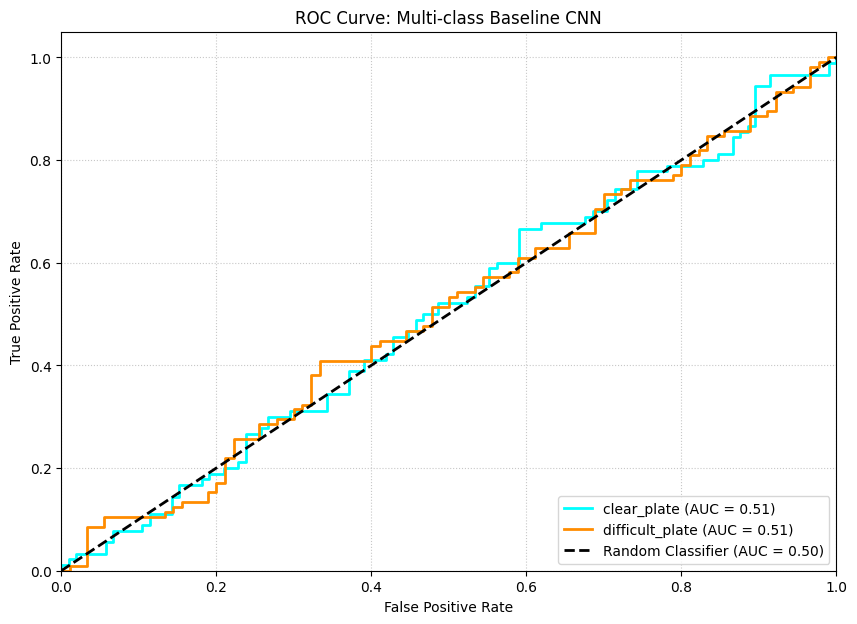

In [ ]:
plt.figure(figsize=(10, 7))
colors = cycle(['aqua', 'darkorange', 'cornflowerblue', 'red'])

for i, class_idx in enumerate(present_classes):
    fpr, tpr, _ = roc_curve(y_true_onehot[:, class_idx], y_prob_arr[:, class_idx])
    roc_auc_val = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        color=next(colors),
        lw=2,
        label=f'{target_classes[class_idx]} (AUC = {roc_auc_val:.2f})'
    )

# Reference line for a random classifier
plt.plot([0, 1], [0, 1], 'k--', lw=2, label='Random Classifier (AUC = 0.50)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve: Multi-class Baseline CNN')
plt.legend(loc='lower right')
plt.grid(True, linestyle=':', alpha=0.7)
plt.show()

### Step 7e: Precision-Recall Curve
The Precision-Recall curve is particularly useful for evaluating models on datasets where class distribution might be imbalanced. It shows the tradeoff between precision (exactness) and recall (completeness) for different thresholds.

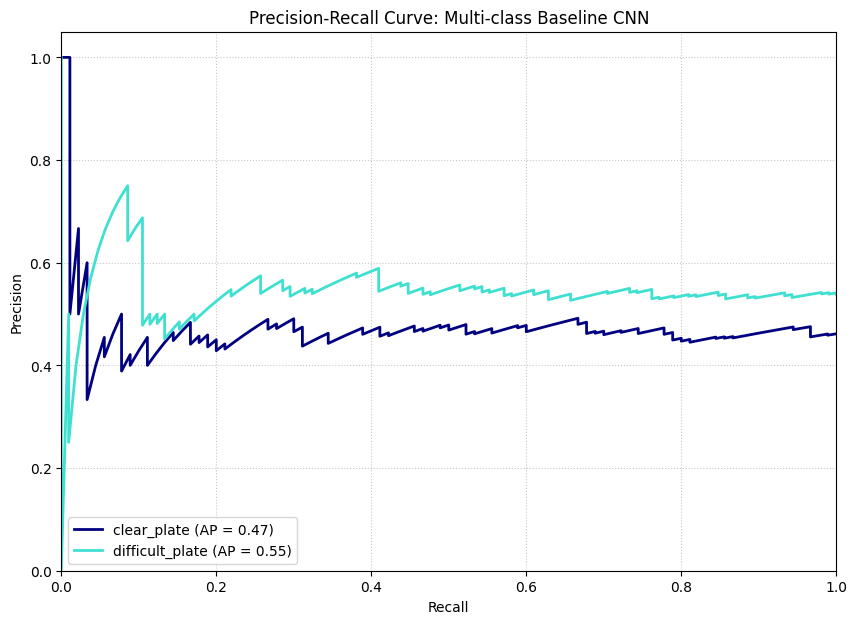

In [ ]:
# Compute Precision-Recall curve and Average Precision (AP) for each class
plt.figure(figsize=(10, 7))
colors = cycle(['navy', 'turquoise', 'darkorange', 'teal'])

for i, class_idx in enumerate(present_classes):
    precision_vals, recall_vals, _ = precision_recall_curve(
        y_true_onehot[:, class_idx],
        y_prob_arr[:, class_idx]
    )
    ap_score = average_precision_score(
        y_true_onehot[:, class_idx],
        y_prob_arr[:, class_idx]
    )

    plt.plot(
        recall_vals,
        precision_vals,
        color=next(colors),
        lw=2,
        label=f'{target_classes[class_idx]} (AP = {ap_score:.2f})'
    )

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve: Multi-class Baseline CNN')
plt.legend(loc='lower left')
plt.grid(True, linestyle=':', alpha=0.7)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.show()

## Step 8: YOLOv8 Environment Setup
Transitioning to Object Detection, we install the required Ultralytics package. We then create the necessary directory structure (images and labels) and generate the `data.yaml` configuration file required for YOLO training.

In [ ]:
!pip install -q ultralytics

In [ ]:
from ultralytics import YOLO
import torch

det_dataset_path = root_path / "detection_dataset"

# Prepare YOLO directory structure
for split in ["train", "val", "test"]:
    (det_dataset_path / f"images/{split}").mkdir(parents=True, exist_ok=True)
    (det_dataset_path / f"labels/{split}").mkdir(parents=True, exist_ok=True)

# Generate data.yaml configuration file for YOLO
data_yaml = Path("/content/data.yaml")
data_yaml.write_text(f"""
path: {det_dataset_path}
train: images/train
val: images/val
test: images/test
names:
  0: plate
""".strip())

print(f"YOLO configuration saved to {data_yaml}")

YOLO configuration saved to /content/data.yaml


## Step 9: Dataset Splitting and Distribution
In this step, we prepare the images for the YOLO model. We gather all files from the 'clear_plate' and 'difficult_plate' folders, shuffle them to ensure the model sees a variety of conditions, and split them into a 70/15/15 ratio for training, validation, and testing.

In [ ]:
# Define target extensions and gather all source images
extensions = (".jpg", ".jpeg", ".png")
all_source_images = []

for folder in [clear_plate_path, difficult_plate_path]:
    if folder.exists():
        all_source_images.extend([p for p in folder.glob("*") if p.suffix.lower() in extensions])

In [ ]:
# Shuffle and calculate split indices
random.seed(seed)
random.shuffle(all_source_images)

total_images = len(all_source_images)
train_idx = int(0.7 * total_images)
val_idx = int(0.85 * total_images)

# Split the list into three groups
train_files = all_source_images[:train_idx]
val_files = all_source_images[train_idx:val_idx]
test_files = all_source_images[val_idx:]

In [ ]:
# Helper function to copy files to their respective YOLO image folders
def move_to_yolo(file_list, split_name):
    target_dir = det_dataset_path / "images" / split_name
    target_dir.mkdir(parents=True, exist_ok=True)
    for f in file_list:
        shutil.copy2(f, target_dir / f.name)

In [ ]:
# Execute the copying process
move_to_yolo(train_files, "train")
move_to_yolo(val_files, "val")
move_to_yolo(test_files, "test")

print(f"Successfully distributed {total_images} images:")
print(f" - Training: {len(train_files)}")
print(f" - Validation: {len(val_files)}")
print(f" - Testing: {len(test_files)}")

Successfully distributed 1292 images:
 - Training: 904
 - Validation: 194
 - Testing: 194


## Step 10: Verification of YOLO Dataset
Before starting the YOLO training process, we run a check to ensure that the images were copied correctly and to see if corresponding label files (.txt) are present in the labels directory.

In [ ]:
# Check counts for each split
for split in ["train", "val", "test"]:
    img_count = len(list((det_dataset_path / "images" / split).glob("*")))
    lbl_count = len(list((det_dataset_path / "labels" / split).glob("*.txt")))

    print(f"Split: {split.upper()}")
    print(f"  Images found: {img_count}")
    print(f"  Labels found: {lbl_count}")

    if img_count > 0 and lbl_count == 0:
        print("  Status: Images present but labels are missing. Upload .txt files to proceed.")
    else:
        print("  Status: Ready")

Split: TRAIN
  Images found: 904
  Labels found: 0
  Status: Images present but labels are missing. Upload .txt files to proceed.
Split: VAL
  Images found: 194
  Labels found: 0
  Status: Images present but labels are missing. Upload .txt files to proceed.
Split: TEST
  Images found: 194
  Labels found: 0
  Status: Images present but labels are missing. Upload .txt files to proceed.


## Step 11: Training the YOLOv8 Model
We initialize the YOLOv8 Nano model and begin training.

In [ ]:
# Initialize and train YOLOv8 Nano
device = 0 if torch.cuda.is_available() else "cpu"
print(f"Training on device: {device}")

yolo_model = YOLO("yolov8n.pt")

yolo_model.train(
        data=str(data_yaml),
        epochs=50,
        imgsz=640,
        batch=32,
        device=device,
        project="/content/runs",
        name="yolov8_plate",
        exist_ok=True
    )

Training on device: 0
Ultralytics 8.4.23 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8_plate, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=10

/usr/local/lib/python3.12/dist-packages/ultralytics/utils/metrics.py:839: RuntimeWarning: Mean of empty slice.
  i = smooth(f1_curve.mean(0), 0.1).argmax()  # max F1 index
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:130: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(



      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       2/50      4.73G          0        133          0          0        640: 100% ━━━━━━━━━━━━ 29/29 1.8it/s 16.4s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 3.1it/s 1.3s
                   all        194          0          0          0          0          0
WARNING ⚠️ no labels found in detect set, cannot compute metrics without labels


/usr/local/lib/python3.12/dist-packages/ultralytics/utils/metrics.py:839: RuntimeWarning: Mean of empty slice.
  i = smooth(f1_curve.mean(0), 0.1).argmax()  # max F1 index
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:130: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(



      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/50      4.73G          0      97.07          0          0        640: 100% ━━━━━━━━━━━━ 29/29 1.7it/s 17.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.8it/s 1.4s
                   all        194          0          0          0          0          0
WARNING ⚠️ no labels found in detect set, cannot compute metrics without labels


/usr/local/lib/python3.12/dist-packages/ultralytics/utils/metrics.py:839: RuntimeWarning: Mean of empty slice.
  i = smooth(f1_curve.mean(0), 0.1).argmax()  # max F1 index
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:130: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(


... (94 outputs left out)


50 epochs completed in 0.263 hours.
Optimizer stripped from /content/runs/yolov8_plate/weights/last.pt, 6.2MB
Optimizer stripped from /content/runs/yolov8_plate/weights/best.pt, 6.2MB

Validating /content/runs/yolov8_plate/weights/best.pt...
Ultralytics 8.4.23 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.5it/s 1.6s


/usr/local/lib/python3.12/dist-packages/ultralytics/utils/metrics.py:657: RuntimeWarning: Mean of empty slice.
  ax.plot(px, py.mean(1), linewidth=3, color="blue", label=f"all classes {ap[:, 0].mean():.3f} mAP@0.5")
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:138: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/usr/local/lib/python3.12/dist-packages/ultralytics/utils/metrics.py:703: RuntimeWarning: Mean of empty slice.
  y = smooth(py.mean(0), 0.1)
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:130: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(
/usr/local/lib/python3.12/dist-packages/ultralytics/utils/metrics.py:703: RuntimeWarning: Mean of empty slice.
  y = smooth(py.mean(0), 0.1)
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:130: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(
/usr/local/lib/python3.12/dist-packages/ultraly

                   all        194          0          0          0          0          0
WARNING ⚠️ no labels found in detect set, cannot compute metrics without labels
Speed: 0.2ms preprocess, 3.5ms inference, 0.0ms loss, 1.5ms postprocess per image
Results saved to /content/runs/yolov8_plate


ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([], dtype=int64)
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7bed3011b830>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
        

## Step 12: Analyzing YOLO Training Results
After training, YOLOv8 generates a results file that tracks loss and accuracy metrics over time. This visualization allows us to confirm that the model converged correctly and to identify any potential overfitting.

Displaying Training Metrics (Loss, mAP, Precision, Recall):


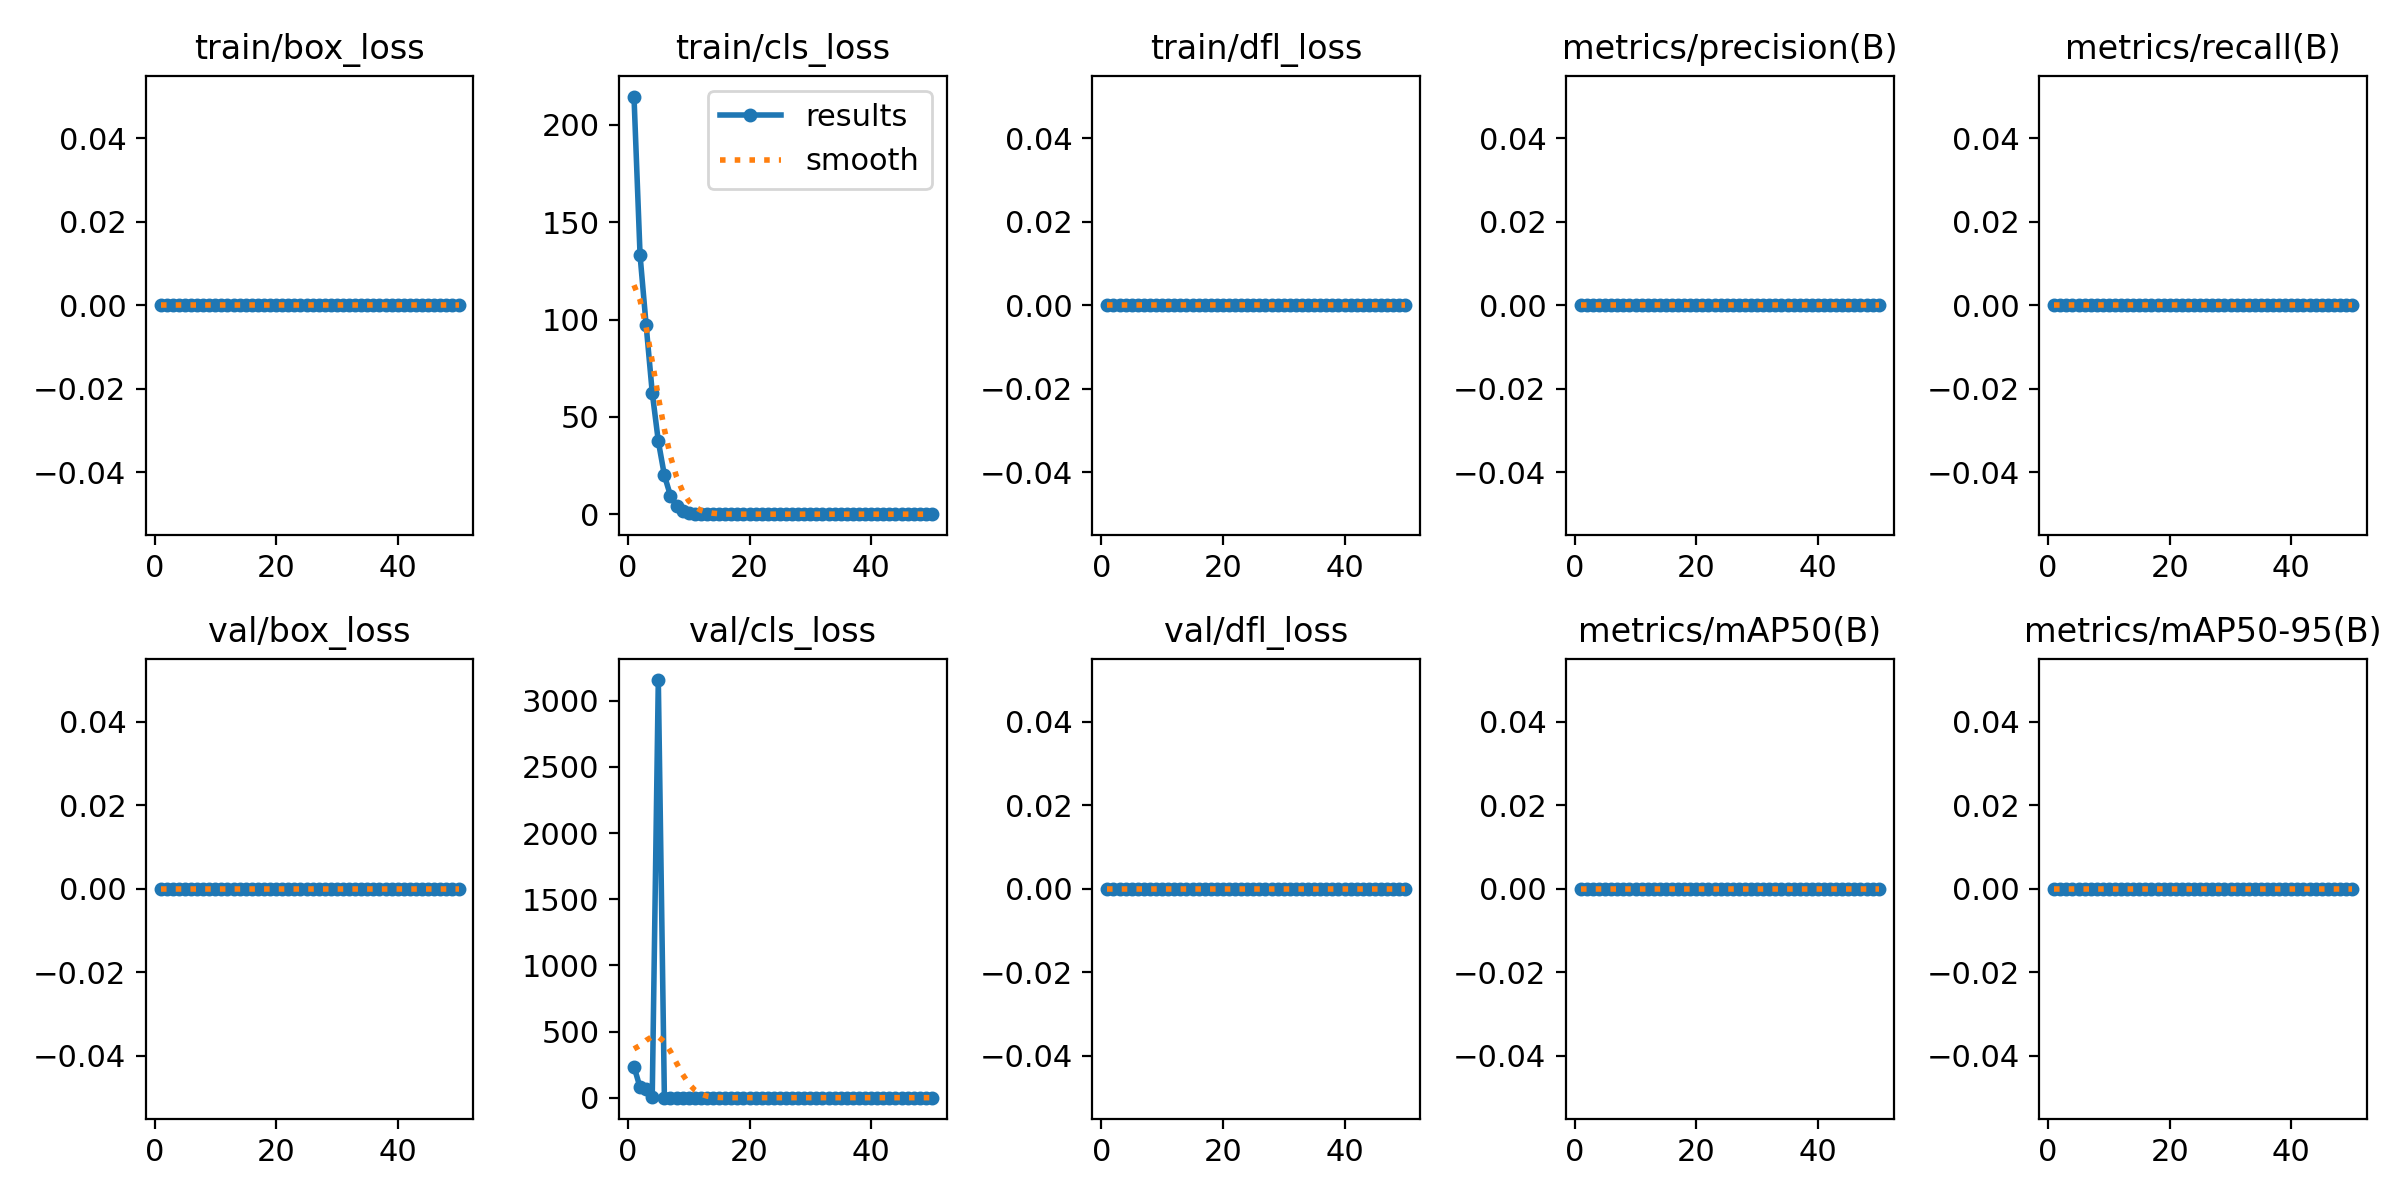

In [ ]:
# Path to the results visualization generated by YOLO
results_path = Path("/content/runs/yolov8_plate/results.png")

if results_path.exists():
    from IPython.display import Image, display
    print("Displaying Training Metrics (Loss, mAP, Precision, Recall):")
    display(Image(filename=str(results_path), width=1000))
else:
    print("Results image not found. Ensure the training finished and the path is correct.")

## Step 13: Validating Model Performance on the Test Set
In this step, we load the 'best' weights saved during training and run an evaluation against the unseen Test Set. This provides the final mean Average Precision (mAP) scores, which are the standard benchmark for object detection accuracy.

In [ ]:
# Load the best weights from the previous training run
best_model_path = "/content/runs/yolov8_plate/weights/best.pt"

if os.path.exists(best_model_path):
    yolo_eval_model = YOLO(best_model_path)

    print("Running evaluation on the Test Split...")
    test_metrics = yolo_eval_model.val(data=str(data_yaml), split="test")

    print(f"\nTest mAP 50: {test_metrics.box.map50:.4f}")
    print(f"Test mAP 50-95: {test_metrics.box.map:.4f}")
else:
    print("Weights file not found. Check the project directory.")

Running evaluation on the Test Split...
Ultralytics 8.4.23 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.7±0.2 ms, read: 14.6±5.5 MB/s, size: 71.7 KB)
val: Scanning /content/drive/MyDrive/Colab Notebooks/Vehicle Number Plate Detection Dataset/detection_dataset/labels/test.cache... 0 images, 194 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 194/194 62.6Mit/s 0.0s
WARNING ⚠️ Labels are missing or empty in /content/drive/MyDrive/Colab Notebooks/Vehicle Number Plate Detection Dataset/detection_dataset/labels/test.cache, training may not work correctly. See https://docs.ultralytics.com/datasets for dataset formatting guidance.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 4.2it/s 3.1s


/usr/local/lib/python3.12/dist-packages/ultralytics/utils/metrics.py:657: RuntimeWarning: Mean of empty slice.
  ax.plot(px, py.mean(1), linewidth=3, color="blue", label=f"all classes {ap[:, 0].mean():.3f} mAP@0.5")
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:138: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/usr/local/lib/python3.12/dist-packages/ultralytics/utils/metrics.py:703: RuntimeWarning: Mean of empty slice.
  y = smooth(py.mean(0), 0.1)
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:130: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(
/usr/local/lib/python3.12/dist-packages/ultralytics/utils/metrics.py:703: RuntimeWarning: Mean of empty slice.
  y = smooth(py.mean(0), 0.1)
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:130: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(
/usr/local/lib/python3.12/dist-packages/ultraly

                   all        194          0          0          0          0          0
WARNING ⚠️ no labels found in detect set, cannot compute metrics without labels
Speed: 5.7ms preprocess, 6.1ms inference, 0.0ms loss, 0.5ms postprocess per image
Results saved to /content/runs/detect/val

Test mAP 50: 0.0000
Test mAP 50-95: 0.0000


## Step 14: Visualizing YOLO Predictions
To see how the model performs in practice, we run inference on sample images from the test set. This visual check confirms if the bounding boxes are correctly tightly fitted around the number plates.

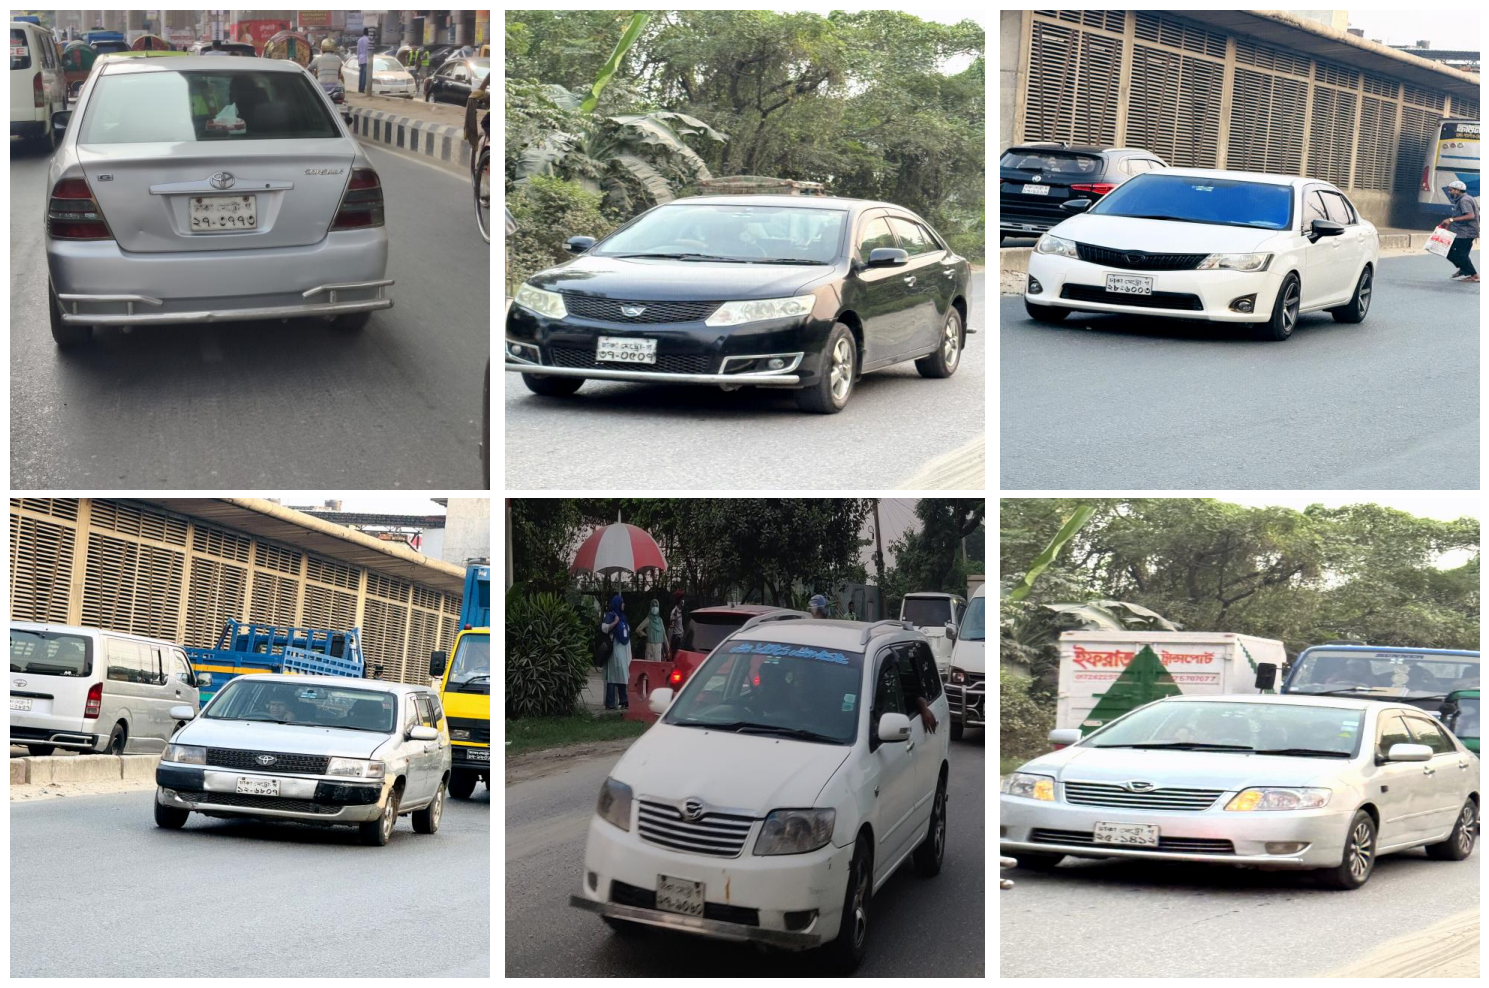

In [ ]:
# Select random images from the test folder
test_images = list((det_dataset_path / "images/test").glob("*.*"))
samples = random.sample(test_images, k=min(6, len(test_images)))

plt.figure(figsize=(15, 10))

for i, img_path in enumerate(samples):
    # Run prediction
    results = yolo_eval_model.predict(source=str(img_path), conf=0.3, verbose=False)
    result = results[0]

    # Convert for plotting
    img_rgb = cv2.cvtColor(result.orig_img, cv2.COLOR_BGR2RGB)
    plt.subplot(2, 3, i + 1)
    plt.imshow(img_rgb)

    # Draw boxes
    for box in result.boxes:
        coords = box.xyxy[0].cpu().numpy()
        rect = plt.Rectangle((coords[0], coords[1]), coords[2]-coords[0], coords[3]-coords[1],
                             fill=False, color='lime', linewidth=3)
        plt.gca().add_patch(rect)
        plt.title(f"Conf: {box.conf[0].cpu().numpy():.2f}")

    plt.axis("off")

plt.tight_layout()
plt.show()

## Step 12: Classical Computer Vision Fallback
If YOLO bounding box labels are currently unavailable, classical Computer Vision techniques can be utilized as a baseline for plate localization. This function uses bilateral filtering, edge detection (Canny), and contour analysis to find plate-like rectangular regions.

In [ ]:
# Get test images
test_images = sorted(list((det_dataset_path / "images/test").glob("*.*")))
sample_images = random.sample(test_images, k=min(6, len(test_images)))

def find_plate(image):
    """
    Detect rectangular plate-like regions using basic edge detection
    and contour filtering.
    """
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    gray = cv2.bilateralFilter(gray, 11, 17, 17)
    edges = cv2.Canny(gray, 30, 200)

    contours, _ = cv2.findContours(edges.copy(), cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)
    contours = sorted(contours, key=cv2.contourArea, reverse=True)[:10]

    boxes = []
    for c in contours:
        perimeter = cv2.arcLength(c, True)
        approx = cv2.approxPolyDP(c, 0.02 * perimeter, True)

        # Check for rectangular contour
        if len(approx) == 4:
            x, y, w, h = cv2.boundingRect(approx)

            # Basic size filter
            if w > 60 and h > 15:
                boxes.append((x, y, x + w, y + h))

    return boxes

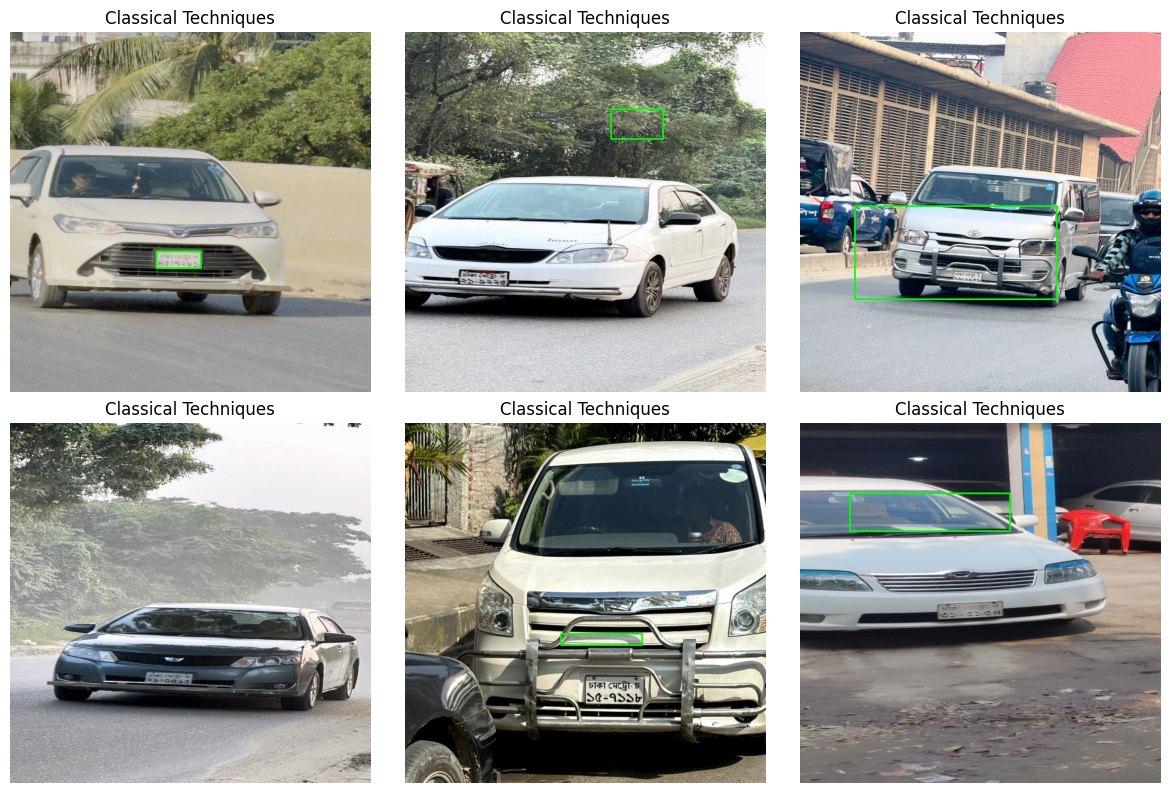

In [ ]:
# Visualize results
plt.figure(figsize=(12, 8))

for i, img_path in enumerate(sample_images):
    image = cv2.imread(str(img_path))
    boxes = find_plate(image)

    # Draw the first candidate box (if any)
    if boxes:
        x1, y1, x2, y2 = boxes[0]
        cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)

    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.subplot(2, 3, i + 1)
    plt.imshow(image_rgb)
    plt.title("Classical Techniques")
    plt.axis("off")

plt.tight_layout()
plt.show()